# Диагностика обучения MLP
Лабораторная работа № 1 по DLNN. Исследуем активации, инициализацию, заданные режимы оптимизации и глубину MLP на `make_moons`.

Все 12 запусков выполняются на CPU. Данные и разбиение фиксированы; test используется только после выбора модели по validation loss эпохи 100. Последовательный запуск всех ячеек создаёт таблицы в `results/` и графики в `figures/`.


In [1]:
from pathlib import Path
from dataclasses import dataclass, asdict
import copy
import csv
import json
import platform
import importlib.metadata
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Общие условия всех экспериментов.
torch.set_num_threads(1)
DEVICE = torch.device("cpu")
SEEDS = (11, 29)
EPOCHS = 100
BATCH_SIZE = 128
RESULTS = Path("results")
FIGURES = Path("figures")
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10})
versions = {name: importlib.metadata.version(name) for name in
            ("torch", "numpy", "scikit-learn", "matplotlib", "nbformat", "nbclient", "ipykernel")}
environment = {"python": platform.python_version(), "device": str(DEVICE),
               "torch_num_threads": torch.get_num_threads(), "versions": versions}
(RESULTS / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
print(json.dumps(environment, indent=2))


{
  "python": "3.12.14",
  "device": "cpu",
  "torch_num_threads": 1,
  "versions": {
    "torch": "2.15.0",
    "numpy": "2.5.4",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.4.0"
  }
}


## 1. Данные и первичная диагностика
Дважды применяем стратифицированное разбиение: сначала 20% в test, затем 25% остатка в validation. Масштабирование обучается только на train: статистики validation и test не должны влиять на подготовку модели. Порядок train сохраняется для контрольного batch.


{
  "sizes": {
    "train": 1440,
    "validation": 480,
    "test": 480
  },
  "class_counts": {
    "train": [
      720,
      720
    ],
    "validation": [
      240,
      240
    ],
    "test": [
      240,
      240
    ]
  },
  "train_mean": [
    2.0662484069412636e-17,
    6.215706961477786e-16
  ],
  "train_std": [
    1.0000000000000004,
    0.9999999999999989
  ]
}


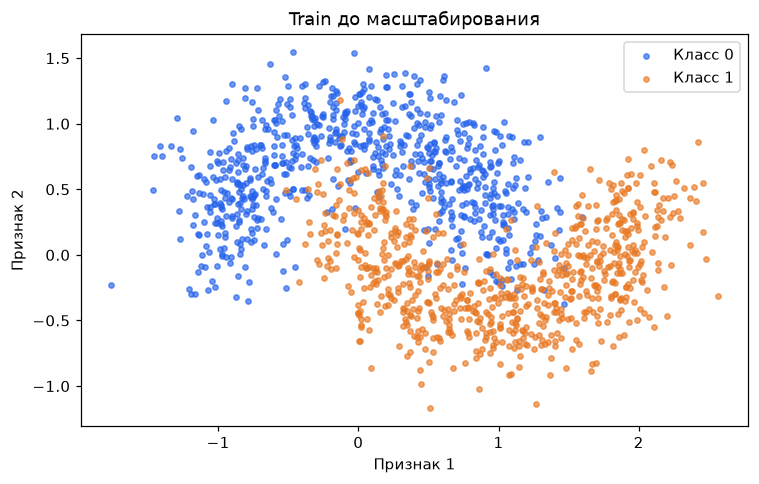

In [2]:
X, y = make_moons(n_samples=2400, noise=0.25, random_state=2026)
X_remaining, X_test_raw, y_remaining, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2026, stratify=y)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_remaining, y_remaining, test_size=0.25, random_state=2026, stratify=y_remaining)
scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)
assert (len(y_train), len(y_val), len(y_test)) == (1440, 480, 480)
class_counts = {name: np.bincount(labels, minlength=2).tolist()
                for name, labels in (("train", y_train), ("validation", y_val), ("test", y_test))}
assert all(min(counts) > 0 for counts in class_counts.values())
assert np.allclose(X_train.mean(axis=0), 0, atol=1e-12)
assert np.allclose(X_train.std(axis=0), 1, atol=1e-12)
data_diagnostics = {"sizes": {"train": 1440, "validation": 480, "test": 480},
                    "class_counts": class_counts,
                    "train_mean": X_train.mean(axis=0).tolist(),
                    "train_std": X_train.std(axis=0).tolist()}
(RESULTS / "data_diagnostics.json").write_text(json.dumps(data_diagnostics, indent=2), encoding="utf-8")
print(json.dumps(data_diagnostics, indent=2))
train_x = torch.tensor(X_train, dtype=torch.float32, device=DEVICE)
val_x = torch.tensor(X_val, dtype=torch.float32, device=DEVICE)
test_x = torch.tensor(X_test, dtype=torch.float32, device=DEVICE)
train_y = torch.tensor(y_train, dtype=torch.long, device=DEVICE)
val_y = torch.tensor(y_val, dtype=torch.long, device=DEVICE)
test_y = torch.tensor(y_test, dtype=torch.long, device=DEVICE)
probe_x, probe_y = train_x[:128], train_y[:128]
train_dataset = TensorDataset(train_x, train_y)

fig, ax = plt.subplots(figsize=(7, 4.5))
for label, color in ((0, "#2563eb"), (1, "#e87924")):
    mask = y_train == label
    ax.scatter(X_train_raw[mask, 0], X_train_raw[mask, 1], s=12, alpha=0.65,
               color=color, label=f"Класс {label}")
ax.set(xlabel="Признак 1", ylabel="Признак 2", title="Train до масштабирования")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "train_scatter.png")
plt.show()


## 2. Модель, инициализация и проверки
Для скрытого слоя $h_l=\varphi(W_lh_{l-1}+b_l)$, $h_0=x$. Выход — два линейных логита; softmax перед `CrossEntropyLoss` не применяется.

Число параметров: $N(L)=(2\cdot32+32)+(L-1)(32\cdot32+32)+(32\cdot2+2)$.
При $L=1$: 162; при $L=6$: 5442. Все bias равны нулю. Для выхода всегда используется Xavier normal с gain=1, независимо от скрытой активации.


In [3]:
@dataclass(frozen=True)
class Config:
    name: str
    depth: int
    activation: str
    initialization: str
    optimizer: str
    lr: float

CONFIGS = (
    Config("A", 6, "Sigmoid", "xavier", "Adam", 0.003),
    Config("B", 6, "Tanh", "xavier", "Adam", 0.003),
    Config("C", 6, "ReLU", "xavier", "Adam", 0.003),
    Config("D", 6, "ReLU", "he", "Adam", 0.003),
    Config("E", 6, "ReLU", "he", "SGD", 0.05),
    Config("F", 1, "ReLU", "he", "Adam", 0.003),
)

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.hidden = nn.ModuleList([
            nn.Linear(2 if layer == 0 else 32, 32) for layer in range(config.depth)])
        self.activation = {"Sigmoid": nn.Sigmoid, "Tanh": nn.Tanh, "ReLU": nn.ReLU}[config.activation]()
        self.output = nn.Linear(32, 2)
        for layer in self.hidden:
            if config.initialization == "xavier":
                nn.init.xavier_normal_(layer.weight, gain=1.0)
            elif config.initialization == "he":
                nn.init.kaiming_normal_(layer.weight, mode="fan_in", nonlinearity="relu")
            else:
                raise ValueError(config.initialization)
            nn.init.zeros_(layer.bias)
        nn.init.xavier_normal_(self.output.weight, gain=1.0)
        nn.init.zeros_(self.output.bias)

    def forward(self, x):
        for layer in self.hidden:
            x = self.activation(layer(x))
        return self.output(x)

criterion = nn.CrossEntropyLoss(reduction="mean")
checks = []
for config in (CONFIGS[0], CONFIGS[-1]):
    torch.manual_seed(11)
    model = MLP(config).to(DEVICE)
    logits = model(train_x[:8])
    loss = criterion(logits, train_y[:8])
    expected = 162 + (config.depth - 1) * 1056
    actual = sum(p.numel() for p in model.parameters())
    assert train_x[:8].shape == logits.shape == (8, 2)
    assert loss.ndim == 0 and actual == expected
    loss.backward()
    for layer in model.hidden:
        assert layer.weight.grad is not None
        assert layer.weight.grad.shape == layer.weight.shape
        assert torch.isfinite(layer.weight.grad).all()
    checks.append({"depth": config.depth, "parameters": actual,
                   "input_shape": list(train_x[:8].shape), "output_shape": list(logits.shape),
                   "loss_scalar": loss.ndim == 0, "hidden_gradients_valid": True})
print(checks)
(RESULTS / "self_checks.json").write_text(json.dumps(checks, indent=2), encoding="utf-8")


[{'depth': 6, 'parameters': 5442, 'input_shape': [8, 2], 'output_shape': [8, 2], 'loss_scalar': True, 'hidden_gradients_valid': True}, {'depth': 1, 'parameters': 162, 'input_shape': [8, 2], 'output_shape': [8, 2], 'loss_scalar': True, 'hidden_gradients_valid': True}]


401

## 3. Цикл обучения и диагностика градиентов
Каждая эпоха состоит из шагов `zero_grad → forward → loss → backward → optimizer.step`. До обучения и после каждой эпохи метрики вычисляются на полных выборках в `eval/no_grad`; accuracy — доля правильных ответов.

На эпохах 0, 20 и 100 для A/C/D выполняем отдельный backward на первых 128 объектах train. Норма Фробениуса считается только для матрицы весов скрытого слоя. Градиенты очищаются до и после измерения, optimizer.step не вызывается. Режим модели восстанавливается.


In [4]:
def evaluate(model, x, y):
    model.eval()
    with torch.no_grad():
        logits = model(x)
        loss = criterion(logits, y)
        accuracy = (logits.argmax(dim=1) == y).float().mean()
    assert torch.isfinite(loss)
    return loss.item(), accuracy.item()

def probe_gradients(model, config, seed, epoch):
    was_training = model.training
    model.eval()
    model.zero_grad(set_to_none=True)
    loss = criterion(model(probe_x), probe_y)
    assert torch.isfinite(loss)
    loss.backward()
    rows = []
    for index, layer in enumerate(model.hidden, start=1):
        gradient = layer.weight.grad
        assert gradient is not None and gradient.shape == layer.weight.shape
        assert torch.isfinite(gradient).all()
        norm = torch.linalg.matrix_norm(gradient, ord="fro").item()
        if norm == 0.0:
            assert torch.count_nonzero(gradient).item() == 0
        rows.append({"config": config.name, "seed": seed, "epoch": epoch,
                     "layer": index, "gradient_norm": norm})
    model.zero_grad(set_to_none=True)
    model.train(was_training)
    return rows

def train_run(config, seed):
    torch.manual_seed(seed)
    model = MLP(config).to(DEVICE)
    generator = torch.Generator().manual_seed(10000 + seed)
    loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                        generator=generator, num_workers=0)
    optimizer = (torch.optim.Adam(model.parameters(), lr=config.lr)
                 if config.optimizer == "Adam" else
                 torch.optim.SGD(model.parameters(), lr=config.lr, momentum=0))
    history, gradients = [], []
    for epoch in range(EPOCHS + 1):
        if epoch > 0:
            model.train()
            for batch_x, batch_y in loader:
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(batch_x), batch_y)
                assert torch.isfinite(loss)
                loss.backward()
                optimizer.step()
        train_loss, train_accuracy = evaluate(model, train_x, train_y)
        val_loss, val_accuracy = evaluate(model, val_x, val_y)
        history.append({"config": config.name, "seed": seed, "epoch": epoch,
                        "train_loss": train_loss, "train_accuracy": train_accuracy,
                        "val_loss": val_loss, "val_accuracy": val_accuracy})
        if config.name in ("A", "C", "D") and epoch in (0, 20, 100):
            gradients.extend(probe_gradients(model, config, seed, epoch))
    return history, gradients, copy.deepcopy(model.state_dict())

def write_csv(path, rows):
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def markdown_table(rows, fields):
    lines = ["| " + " | ".join(fields) + " |", "| " + " | ".join(["---"] * len(fields)) + " |"]
    for row in rows:
        values = [f"{row[field]:.6f}" if isinstance(row[field], float) else str(row[field]) for field in fields]
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)


In [5]:
# Полный набор экспериментов: шесть конфигураций, два seed, 100 эпох.
metrics, gradients, final_states = [], [], {}
for config in CONFIGS:
    for seed in SEEDS:
        history, measured_gradients, state = train_run(config, seed)
        metrics.extend(history)
        gradients.extend(measured_gradients)
        final_states[(config.name, seed)] = state
        final = history[-1]
        print(f"{config.name}, seed={seed}: val_loss={final['val_loss']:.6f}, "
              f"val_accuracy={final['val_accuracy']:.6f}")
assert len(metrics) == 1212 and len(gradients) == 108
assert len({(r['config'], r['seed'], r['epoch']) for r in metrics}) == 1212
assert all(0 <= r[key] <= 1 for r in metrics for key in ('train_accuracy', 'val_accuracy'))
write_csv(RESULTS / "metrics.csv", metrics)
write_csv(RESULTS / "gradients.csv", gradients)
summary = [row for row in metrics if row["epoch"] == 100]
mean_validation = [{"config": config.name, "mean_val_loss": float(np.mean([
    row["val_loss"] for row in summary if row["config"] == config.name]))} for config in CONFIGS]
write_csv(RESULTS / "summary.csv", summary)
write_csv(RESULTS / "mean_validation.csv", mean_validation)
(RESULTS / "configurations.json").write_text(json.dumps([asdict(c) for c in CONFIGS], indent=2), encoding="utf-8")
display(Markdown(markdown_table(summary, list(summary[0]))))
display(Markdown(markdown_table(mean_validation, list(mean_validation[0]))))


A, seed=11: val_loss=0.190750, val_accuracy=0.916667


A, seed=29: val_loss=0.177103, val_accuracy=0.916667


B, seed=11: val_loss=0.203395, val_accuracy=0.912500


B, seed=29: val_loss=0.189271, val_accuracy=0.918750


C, seed=11: val_loss=0.180691, val_accuracy=0.920833


C, seed=29: val_loss=0.224080, val_accuracy=0.910417


... (4 outputs left out)

F, seed=11: val_loss=0.167788, val_accuracy=0.929167


F, seed=29: val_loss=0.167623, val_accuracy=0.922917


| config | seed | epoch | train_loss | train_accuracy | val_loss | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| A | 11 | 100 | 0.150452 | 0.945833 | 0.190750 | 0.916667 |
| A | 29 | 100 | 0.140309 | 0.945833 | 0.177103 | 0.916667 |
| B | 11 | 100 | 0.146706 | 0.946528 | 0.203395 | 0.912500 |
| B | 29 | 100 | 0.143581 | 0.948611 | 0.189271 | 0.918750 |
| C | 11 | 100 | 0.120760 | 0.951389 | 0.180691 | 0.920833 |
| C | 29 | 100 | 0.129302 | 0.945833 | 0.224080 | 0.910417 |
| D | 11 | 100 | 0.108775 | 0.953472 | 0.212312 | 0.922917 |
| D | 29 | 100 | 0.114085 | 0.952083 | 0.206341 | 0.914583 |
| E | 11 | 100 | 0.254591 | 0.884722 | 0.346126 | 0.858333 |
| E | 29 | 100 | 0.303343 | 0.865278 | 0.355739 | 0.839583 |
| F | 11 | 100 | 0.136744 | 0.949306 | 0.167788 | 0.929167 |
| F | 29 | 100 | 0.138208 | 0.949306 | 0.167623 | 0.922917 |

| config | mean_val_loss |
| --- | --- |
| A | 0.183927 |
| B | 0.196333 |
| C | 0.202386 |
| D | 0.209326 |
| E | 0.350932 |
| F | 0.167705 |

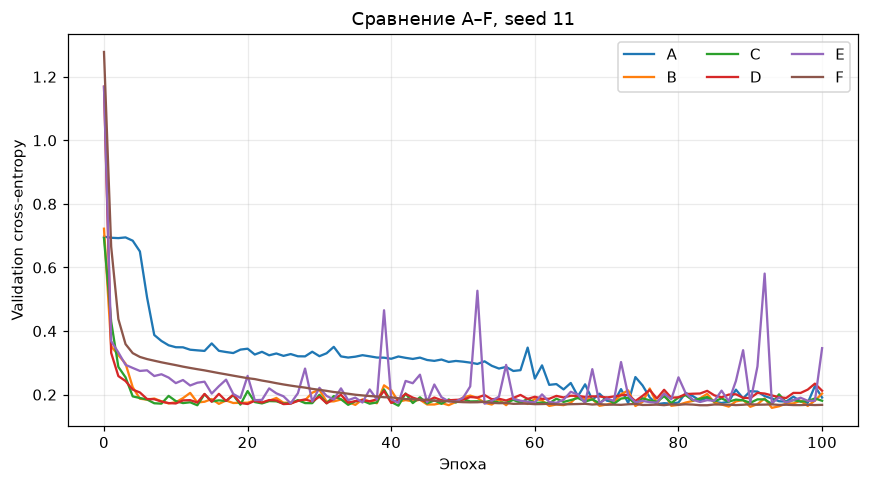

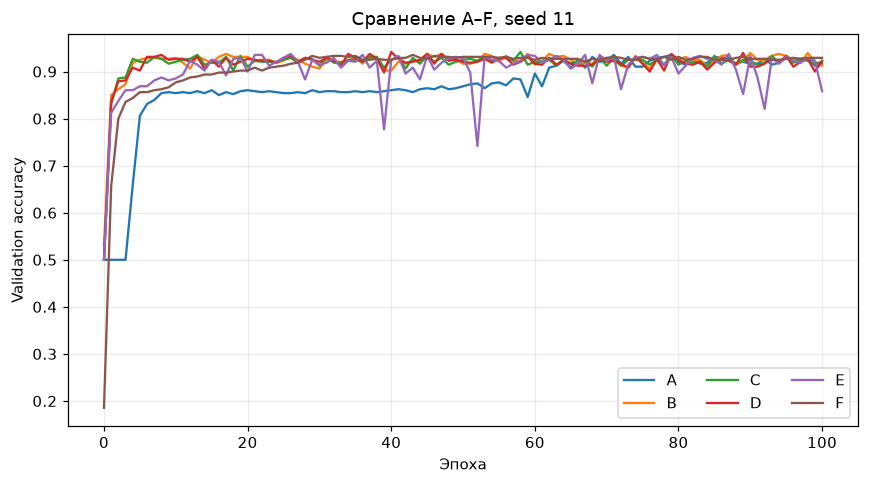

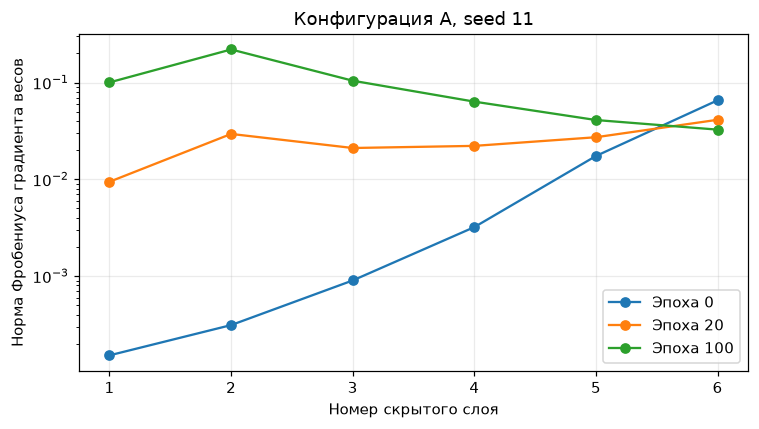

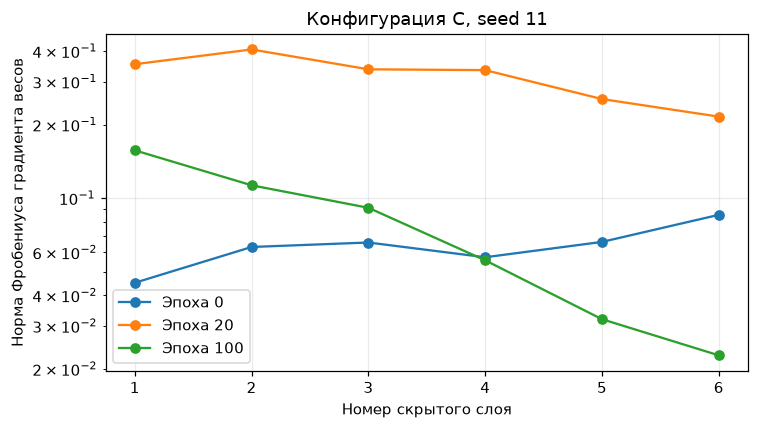

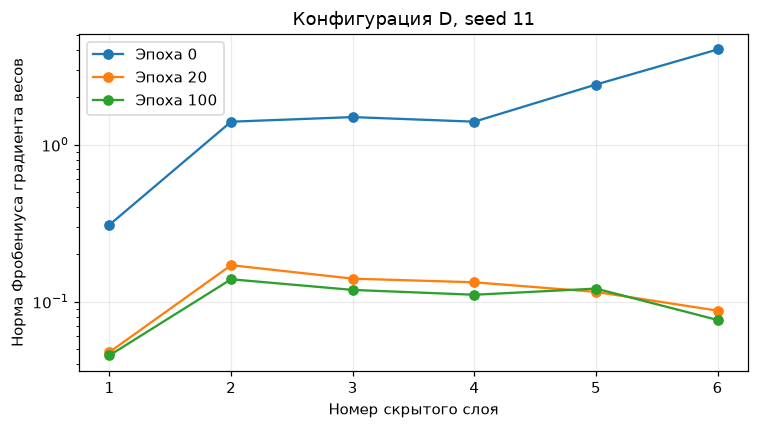

Нулевые нормы: не обнаружены


| config | seed | epoch | layer | gradient_norm |
| --- | --- | --- | --- | --- |
| A | 11 | 0 | 1 | 0.000152 |
| A | 11 | 0 | 2 | 0.000311 |
| A | 11 | 0 | 3 | 0.000901 |
| A | 11 | 0 | 4 | 0.003209 |
| A | 11 | 0 | 5 | 0.017442 |
| A | 11 | 0 | 6 | 0.065648 |
| A | 11 | 20 | 1 | 0.009437 |
| A | 11 | 20 | 2 | 0.029476 |
| A | 11 | 20 | 3 | 0.021088 |
| A | 11 | 20 | 4 | 0.022182 |
| A | 11 | 20 | 5 | 0.027252 |
| A | 11 | 20 | 6 | 0.041275 |
| A | 11 | 100 | 1 | 0.100517 |
| A | 11 | 100 | 2 | 0.220147 |
| A | 11 | 100 | 3 | 0.104640 |
| A | 11 | 100 | 4 | 0.063569 |
| A | 11 | 100 | 5 | 0.041040 |
| A | 11 | 100 | 6 | 0.032653 |
| A | 29 | 0 | 1 | 0.000190 |
| A | 29 | 0 | 2 | 0.000511 |
| A | 29 | 0 | 3 | 0.002002 |
| A | 29 | 0 | 4 | 0.008199 |
| A | 29 | 0 | 5 | 0.032878 |
| A | 29 | 0 | 6 | 0.122300 |
| A | 29 | 20 | 1 | 0.010329 |
| A | 29 | 20 | 2 | 0.059889 |
| A | 29 | 20 | 3 | 0.040632 |
| A | 29 | 20 | 4 | 0.033636 |
| A | 29 | 20 | 5 | 0.031709 |
| A | 29 | 20 | 6 | 0.033726 |
| A | 29 | 100 | 1 | 0.074047 |
| A | 29 | 100 | 2 | 0.037193 |
| A | 29 | 100 | 3 | 0.013374 |
| A | 29 | 100 | 4 | 0.007156 |
| A | 29 | 100 | 5 | 0.003582 |
| A | 29 | 100 | 6 | 0.001929 |
| C | 11 | 0 | 1 | 0.045051 |
| C | 11 | 0 | 2 | 0.063135 |
| C | 11 | 0 | 3 | 0.065851 |
| C | 11 | 0 | 4 | 0.057305 |
| C | 11 | 0 | 5 | 0.066221 |
| C | 11 | 0 | 6 | 0.085482 |
| C | 11 | 20 | 1 | 0.353786 |
| C | 11 | 20 | 2 | 0.406525 |
| C | 11 | 20 | 3 | 0.337132 |
| C | 11 | 20 | 4 | 0.334554 |
| C | 11 | 20 | 5 | 0.254693 |
| C | 11 | 20 | 6 | 0.215765 |
| C | 11 | 100 | 1 | 0.157031 |
| C | 11 | 100 | 2 | 0.112939 |
| C | 11 | 100 | 3 | 0.091347 |
| C | 11 | 100 | 4 | 0.055673 |
| C | 11 | 100 | 5 | 0.031948 |
| C | 11 | 100 | 6 | 0.022725 |
| C | 29 | 0 | 1 | 0.096547 |
| C | 29 | 0 | 2 | 0.140390 |
| C | 29 | 0 | 3 | 0.130168 |
| C | 29 | 0 | 4 | 0.156580 |
| C | 29 | 0 | 5 | 0.114570 |
| C | 29 | 0 | 6 | 0.092547 |
| C | 29 | 20 | 1 | 0.142344 |
| C | 29 | 20 | 2 | 0.173626 |
| C | 29 | 20 | 3 | 0.110537 |
| C | 29 | 20 | 4 | 0.071034 |
| C | 29 | 20 | 5 | 0.042962 |
| C | 29 | 20 | 6 | 0.029368 |
| C | 29 | 100 | 1 | 0.302160 |
| C | 29 | 100 | 2 | 0.264807 |
| C | 29 | 100 | 3 | 0.142714 |
| C | 29 | 100 | 4 | 0.079636 |
| C | 29 | 100 | 5 | 0.047220 |
| C | 29 | 100 | 6 | 0.031373 |
| D | 11 | 0 | 1 | 0.308774 |
| D | 11 | 0 | 2 | 1.399955 |
| D | 11 | 0 | 3 | 1.497978 |
| D | 11 | 0 | 4 | 1.400337 |
| D | 11 | 0 | 5 | 2.413849 |
| D | 11 | 0 | 6 | 4.038586 |
| D | 11 | 20 | 1 | 0.047707 |
| D | 11 | 20 | 2 | 0.170646 |
| D | 11 | 20 | 3 | 0.140110 |
| D | 11 | 20 | 4 | 0.132809 |
| D | 11 | 20 | 5 | 0.115322 |
| D | 11 | 20 | 6 | 0.087625 |
| D | 11 | 100 | 1 | 0.045490 |
| D | 11 | 100 | 2 | 0.138820 |
| D | 11 | 100 | 3 | 0.118758 |
| D | 11 | 100 | 4 | 0.110614 |
| D | 11 | 100 | 5 | 0.121090 |
| D | 11 | 100 | 6 | 0.076427 |
| D | 29 | 0 | 1 | 0.265447 |
| D | 29 | 0 | 2 | 1.095361 |
| D | 29 | 0 | 3 | 1.293327 |
| D | 29 | 0 | 4 | 1.825928 |
| D | 29 | 0 | 5 | 1.007123 |
| D | 29 | 0 | 6 | 0.964312 |
| D | 29 | 20 | 1 | 0.123883 |
| D | 29 | 20 | 2 | 0.433259 |
| D | 29 | 20 | 3 | 0.311290 |
| D | 29 | 20 | 4 | 0.252721 |
| D | 29 | 20 | 5 | 0.207623 |
| D | 29 | 20 | 6 | 0.121438 |
| D | 29 | 100 | 1 | 0.151471 |
| D | 29 | 100 | 2 | 0.460668 |
| D | 29 | 100 | 3 | 0.315784 |
| D | 29 | 100 | 4 | 0.236067 |
| D | 29 | 100 | 5 | 0.143400 |
| D | 29 | 100 | 6 | 0.102211 |

In [6]:
# Сопоставление динамики всех конфигураций при seed 11.
for metric, ylabel, filename in (("val_loss", "Validation cross-entropy", "validation_loss.png"),
                                ("val_accuracy", "Validation accuracy", "validation_accuracy.png")):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for config in CONFIGS:
        rows = [r for r in metrics if r["config"] == config.name and r["seed"] == 11]
        ax.plot([r["epoch"] for r in rows], [r[metric] for r in rows], label=config.name)
    ax.set(xlabel="Эпоха", ylabel=ylabel, title="Сравнение A–F, seed 11")
    ax.grid(alpha=0.25)
    ax.legend(ncol=3)
    fig.tight_layout()
    fig.savefig(FIGURES / filename)
    plt.show()

for name in ("A", "C", "D"):
    fig, ax = plt.subplots(figsize=(7, 4))
    for epoch in (0, 20, 100):
        rows = [r for r in gradients if r["config"] == name and r["seed"] == 11 and r["epoch"] == epoch]
        values = [r["gradient_norm"] if r["gradient_norm"] > 0 else np.nan for r in rows]
        ax.plot([r["layer"] for r in rows], values, marker="o", label=f"Эпоха {epoch}")
    ax.set(xlabel="Номер скрытого слоя", ylabel="Норма Фробениуса градиента весов",
           title=f"Конфигурация {name}, seed 11", yscale="log", xticks=range(1, 7))
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES / f"gradients_{name}.png")
    plt.show()
zero_gradients = [r for r in gradients if r["gradient_norm"] == 0]
print("Нулевые нормы:", zero_gradients if zero_gradients else "не обнаружены")
display(Markdown(markdown_table(gradients, list(gradients[0]))))


## 4. Выбор модели и test
Сначала выбираем конфигурацию по среднему validation loss эпохи 100, затем seed внутри неё. При точном равенстве выбираем более раннюю букву и seed 11. Веса берём строго с эпохи 100. Test не участвует в выборе и не используется для последующей корректировки модели.


{
  "config": "F",
  "seed": 29,
  "epoch": 100,
  "train_loss": 0.1382078379392624,
  "train_accuracy": 0.949305534362793,
  "val_loss": 0.16762325167655945,
  "val_accuracy": 0.9229166507720947,
  "mean_val_loss": 0.1677054986357689,
  "test_loss": 0.13138487935066223,
  "test_accuracy": 0.949999988079071,
  "device": "cpu"
}


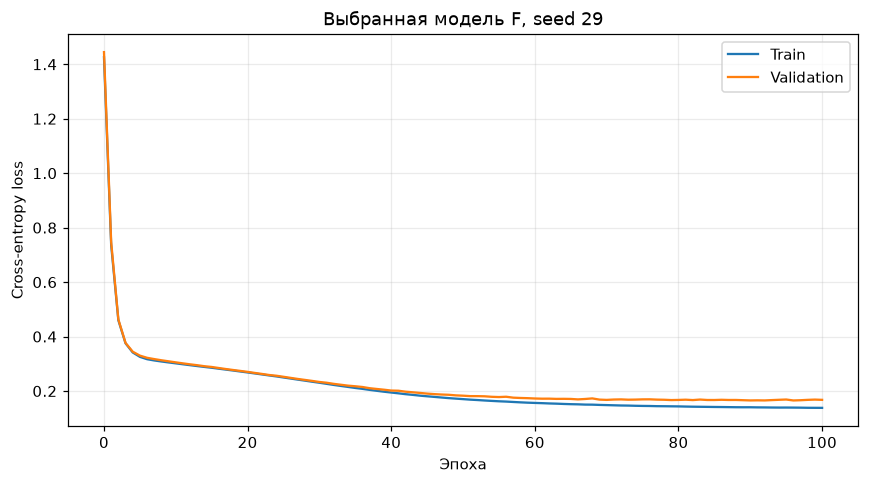

In [7]:
# Выбор только по validation; первая и единственная оценка на test.
best_name = min(mean_validation, key=lambda r: (r["mean_val_loss"], r["config"]))["config"]
best_run = min((r for r in summary if r["config"] == best_name), key=lambda r: (r["val_loss"], r["seed"]))
best_config = next(c for c in CONFIGS if c.name == best_name)
best_model = MLP(best_config).to(DEVICE)
best_model.load_state_dict(final_states[(best_name, best_run["seed"])])
test_loss, test_accuracy = evaluate(best_model, test_x, test_y)
final_evaluation = {**best_run,
                    "mean_val_loss": next(r["mean_val_loss"] for r in mean_validation if r["config"] == best_name),
                    "test_loss": test_loss, "test_accuracy": test_accuracy, "device": str(DEVICE)}
(RESULTS / "final_evaluation.json").write_text(json.dumps(final_evaluation, indent=2), encoding="utf-8")
print(json.dumps(final_evaluation, indent=2))
selected_history = [r for r in metrics if r["config"] == best_name and r["seed"] == best_run["seed"]]
fig, ax = plt.subplots(figsize=(8, 4.5))
for metric, label in (("train_loss", "Train"), ("val_loss", "Validation")):
    ax.plot([r["epoch"] for r in selected_history], [r[metric] for r in selected_history], label=label)
ax.set(xlabel="Эпоха", ylabel="Cross-entropy loss", title=f"Выбранная модель {best_name}, seed {best_run['seed']}")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES / "selected_loss.png")
plt.show()


## 5. Анализ результатов
Численные наблюдения и выводы приведены ниже после выполнения экспериментов. Все сравнения относятся к условиям этой лабораторной; два seed не позволяют делать универсальные утверждения о превосходстве активации, оптимизатора или глубины.


In [8]:
# Компактные численные срезы для проверки динамики обоих seed.
checkpoints = [r for r in metrics if r["epoch"] in (0, 20, 100)]
write_csv(RESULTS / "checkpoints.csv", checkpoints)
display(Markdown(markdown_table(checkpoints, ["config", "seed", "epoch", "train_loss", "val_loss", "val_accuracy"])))
assert len(summary) == 12
assert all(np.isfinite(r[k]) for r in metrics for k in ("train_loss", "val_loss", "train_accuracy", "val_accuracy"))
assert all(np.isfinite(r["gradient_norm"]) for r in gradients)
print("Проверки завершены: 12 запусков, 1212 строк метрик, 108 строк градиентов, test оценён после выбора.")


| config | seed | epoch | train_loss | val_loss | val_accuracy |
| --- | --- | --- | --- | --- | --- |
| A | 11 | 0 | 0.696938 | 0.696936 | 0.500000 |
| A | 11 | 20 | 0.337007 | 0.344482 | 0.860417 |
| A | 11 | 100 | 0.150452 | 0.190750 | 0.916667 |
| A | 29 | 0 | 0.713032 | 0.713032 | 0.500000 |
| A | 29 | 20 | 0.328808 | 0.327096 | 0.856250 |
| A | 29 | 100 | 0.140309 | 0.177103 | 0.916667 |
| B | 11 | 0 | 0.723894 | 0.722032 | 0.531250 |
| B | 11 | 20 | 0.157936 | 0.174530 | 0.931250 |
| B | 11 | 100 | 0.146706 | 0.203395 | 0.912500 |
| B | 29 | 0 | 0.553319 | 0.552536 | 0.741667 |
| B | 29 | 20 | 0.146673 | 0.174112 | 0.931250 |
| B | 29 | 100 | 0.143581 | 0.189271 | 0.918750 |
| C | 11 | 0 | 0.695099 | 0.692205 | 0.500000 |
| C | 11 | 20 | 0.157815 | 0.211160 | 0.910417 |
| C | 11 | 100 | 0.120760 | 0.180691 | 0.920833 |
| C | 29 | 0 | 0.668247 | 0.669177 | 0.806250 |
| C | 29 | 20 | 0.133135 | 0.175529 | 0.931250 |
| C | 29 | 100 | 0.129302 | 0.224080 | 0.910417 |
| D | 11 | 0 | 1.259244 | 1.168772 | 0.500000 |
| D | 11 | 20 | 0.134442 | 0.170414 | 0.927083 |
| D | 11 | 100 | 0.108775 | 0.212312 | 0.922917 |
| D | 29 | 0 | 0.426179 | 0.423548 | 0.806250 |
| D | 29 | 20 | 0.139460 | 0.169050 | 0.939583 |
| D | 29 | 100 | 0.114085 | 0.206341 | 0.914583 |
| E | 11 | 0 | 1.259244 | 1.168772 | 0.500000 |
| E | 11 | 20 | 0.224576 | 0.258995 | 0.900000 |
| E | 11 | 100 | 0.254591 | 0.346126 | 0.858333 |
| E | 29 | 0 | 0.426179 | 0.423548 | 0.806250 |
| E | 29 | 20 | 0.185198 | 0.212239 | 0.929167 |
| E | 29 | 100 | 0.303343 | 0.355739 | 0.839583 |
| F | 11 | 0 | 1.272842 | 1.278046 | 0.185417 |
| F | 11 | 20 | 0.248581 | 0.251769 | 0.902083 |
| F | 11 | 100 | 0.136744 | 0.167788 | 0.929167 |
| F | 29 | 0 | 1.425907 | 1.444737 | 0.202083 |
| F | 29 | 20 | 0.268252 | 0.270378 | 0.893750 |
| F | 29 | 100 | 0.138208 | 0.167623 | 0.922917 |

Проверки завершены: 12 запусков, 1212 строк метрик, 108 строк градиентов, test оценён после выбора.


## 6. Обсуждение экспериментов

**Активации A/B/C.** При seed 11 validation loss на эпохе 1 равен 0.6935 / 0.3522 / 0.4296. Sigmoid в глубокой сети начинает заметно медленнее: порог val_loss < 0.2 впервые достигается на эпохе 66, у Tanh — 5, у ReLU — 4. Для seed 29 порог достигается на эпохах 56 / 4 / 4: начальное отставание A повторяется. На эпохе 100 значения для seed 11 составляют 0.1908 / 0.2034 / 0.1807, accuracy — 0.9167 / 0.9125 / 0.9208; для seed 29 — 0.1771 / 0.1893 / 0.2241 и 0.9167 / 0.9187 / 0.9104. Таким образом, быстрый старт B/C не гарантирует лучшего финального loss, а порядок A/B/C зависит от seed. Средние итоговые val_loss: A 0.1839, B 0.1963, C 0.2024. Выводы относятся к заданному Xavier normal с gain=1.0, а не к оптимальной инициализации каждой активации.

**Инициализация C/D.** Для ReLU He увеличивает начальный масштаб скрытых весов по сравнению с Xavier. В квадратных слоях дисперсия меняется с 1/32 до 2/32, в первом слое с 2/(2+32) до 2/2. Это влияет на активации, логиты и градиенты. При seed 11 начальный val_loss C/D — 0.6922/1.1688, при seed 29 — 0.6692/0.4235: больший масштаб не обязательно улучшает начальный loss. На эпохе 20 D имеет меньший val_loss при обоих seed: 0.1704 против 0.2112 и 0.1690 против 0.1755. Однако на эпохе 100 D хуже C при seed 11 (0.2123 против 0.1807) и лучше при seed 29 (0.2063 против 0.2241). Средние 0.2093 против 0.2024 не подтверждают устойчивого выигрыша He по итоговому validation loss. Train loss D ниже при обоих seed: 0.1088/0.1141 против 0.1208/0.1293.

**Режимы оптимизации D/E.** D и E стартуют с одинаковых весов при одном seed. Adam с lr=0.003 впервые достигает val_loss < 0.2 на эпохах 6/5, SGD с lr=0.05 — на 19/21. Итоговые средние val_loss: 0.2093 и 0.3509. На последнем шаге по эпохам у E наблюдается скачок: seed 11, эпохи 99→100, train_loss 0.1277→0.2546 и val_loss 0.1807→0.3461; seed 29 — 0.1337→0.3033 и 0.1693→0.3557. Одновременное ухудшение train и validation указывает на нестабильность оптимизации заданного режима; это нельзя объяснить только переобучением. Лучшие промежуточные эпохи E показывают, что сеть способна решать задачу, но по условиям оценивается эпоха 100. Сравнение не изолирует влияние оптимизатора: learning rate тоже различается.

**Глубина D/F.** Глубокая D достигает val_loss < 0.2 раньше F: 6/5 против 35/42 эпох. На эпохе 100 train_loss D ниже (0.1088/0.1141 против 0.1367/0.1382), но val_loss выше (0.2123/0.2063 против 0.1678/0.1676). Оба seed согласуются с лучшим итоговым обобщением F по validation loss в данном опыте. Одновременно меняются глубина и число параметров: 5442 против 162 (в 33.6 раза), поэтому отдельный эффект глубины не установлен.

## 7. Объяснение диагностики градиентов

По правилу цепочки ошибка передаётся через произведения матриц весов и производных активаций. Производная Sigmoid не превосходит 1/4; последовательное умножение может сильно ослаблять сигнал к ранним слоям. Производная ReLU равна 1 на положительной ветви и 0 на отрицательной, что меняет характер распространения градиента. Наблюдаемые нормы согласуются с этим механизмом, но не являются отдельным измерением только производных активации.

При seed 11 на эпохе 0 у A нормы первого/шестого слоёв — 0.0001516/0.06565 (первый примерно в 433 раза меньше). У C — 0.04505/0.08548, у D — 0.30877/4.03859. При seed 29 у A — 0.0001902/0.12230 (примерно в 643 раза), у C — 0.09655/0.09255, у D — 0.26545/0.96431. Сильное ослабление ранних градиентов A и увеличение начального масштаба D относительно C повторяются на обоих seed. Монотонное возрастание нормы от слоя к слою у ReLU не является устойчивым свойством.

На эпохе 100 при seed 11 у C первый/шестой градиенты — 0.15703/0.02273, у D — 0.04549/0.07643. При seed 29 — 0.30216/0.03137 и 0.15147/0.10221. Для обоих seed к концу обучения D имеет меньшую норму первого слоя и большую шестого, чем C; начальное увеличение всех норм D не сохраняется для всех слоёв. У A норма первого слоя к эпохе 100 выросла до 0.10052 (seed 11) и 0.07405 (seed 29): маленький начальный градиент затрудняет старт, но не означает невозможность обучения. Полные значения всех шести слоёв на эпохах 0, 20, 100 сохранены в `results/gradients.csv`. Нулевых и неконечных норм не обнаружено.

Для batch размера B градиент весов имеет вид суммы внешних произведений ошибок слоя и его входных активаций: ∂L/∂W_l = (1/B) Σ δ_l,i h_(l−1),iᵀ, если δ обозначает производную индивидуальной потери. Поэтому норма зависит не только от обратного сигнала, но и от входных активаций. Первая матрица содержит 32×2=64 элемента, остальные — 32×32=1024; их сырые нормы нельзя трактовать как сопоставимые величины «на один параметр».

Большая норма на контрольном batch сама по себе не задаёт скорость снижения validation loss. Важны направление обновления, learning rate, адаптивное масштабирование Adam, кривизна функции и различие train-probe и validation. Например, большие начальные нормы D относительно C не дали меньшего среднего validation loss на эпохе 100.

## 8. Итоговая оценка и выводы

Минимальный средний validation loss эпохи 100 получен у F: **0.1677055**. Внутри F выбран seed 29: **0.1676233**, против 0.1677877 у seed 11. Правила разрешения точного равенства предусмотрены в коде, но в этих результатах не потребовались.

| Выборка | Loss | Accuracy |
|---|---:|---:|
| Train | 0.138208 | 0.949306 |
| Validation | 0.167623 | 0.922917 |
| Test | 0.131385 | 0.950000 |

Train loss F/29 снизился с 1.4259 до 0.1382, accuracy выросла с 0.2146 до 0.9493: модель хорошо, но не идеально подогнала шумные данные. У F кривые loss в целом снижаются, без длительного начального плато A и резких финальных скачков E. Разрыв validation−train на эпохе 100 равен 0.0294 по loss и −0.0264 по accuracy. Это умеренное различие между выборками, а не доказательство отсутствия переобучения. Test accuracy 0.95 и loss 0.1314 указывают на хорошее качество на отложенных данных данного разбиения. Более низкий test loss, чем train loss, возможен из-за состава конечных выборок и не означает ошибку; test не использовался при выборе. Validation loss F/29 немного колеблется к концу обучения (0.1655 на эпохе 90 и 0.1676 на 100), поэтому утверждать строго монотонное улучшение нельзя.

Три основных вывода:

1. **Начальное ослабление градиента Sigmoid связано с медленным стартом глубокой сети.** У A отношение норм шестого слоя к первому на эпохе 0 — около 433/643, а порог val_loss < 0.2 достигается на 66/56 эпохах, у B/C — на 4–5. Это согласуется с правилом цепочки; к концу A всё же обучается.
2. **Масштаб инициализации меняет градиенты и оптимизацию, но не гарантирует лучшего обобщения.** При seed 11 He повышает начальную норму первого слоя с 0.04505 до 0.30877 и снижает итоговый train loss с 0.1208 до 0.1088, однако средний val_loss D выше C: 0.2093 против 0.2024.
3. **Более точная подгонка train глубокой сетью не обеспечила лучший validation loss.** D имеет 5442 параметра и train_loss 0.1088/0.1141, F — 162 параметра и 0.1367/0.1382; средний val_loss лучше у F: 0.1677 против 0.2093. Это согласуется с различием способности подгонять train и обобщать; отдельно влияние глубины и числа параметров здесь не разделено.

Недостаточно данных для вывода «Adam всегда лучше SGD» или «один скрытый слой всегда лучше шести». Использованы только два seed, одно разбиение, фиксированные learning rate и ограниченные конфигурации. Для таких утверждений потребовались бы дополнительные seed, разбиения, настройка LR на validation и контролируемое сравнение ёмкости. Эти дополнительные эксперименты в обязательный протокол не входят.
